# **Machine Learning | MP02**
----
**Jay Ballesteros**

November 5th, 2026

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, confusion_matrix, 
                             roc_curve, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
PATH = ('/Users/jballesteros/Documents/git/uchicago-mpp/4_autumn_2026/machine_learning/project_2')
df = pd.read_csv('data/Data-Audit.csv')

df.head()

,Sector_score,PARA_A,Risk_A,PARA_B,Risk_B,Money_Value,Risk_D,Score,Inherent_Risk,Audit_Risk,Risk
0,3.89,4.18,2.508,2.50,0.500,3.38,0.676,2.4,8.574,1.7148,1
1,3.89,0.00,0.000,4.83,0.966,0.94,0.188,2.0,2.554,0.5108,0
2,3.89,0.51,0.102,0.23,0.046,0.00,0.000,2.0,1.548,0.3096,0
3,3.89,0.00,0.000,10.80,6.480,11.75,7.050,4.4,17.530,3.5060,1
4,3.89,0.00,0.000,0.08,0.016,0.00,0.000,2.0,1.416,0.2832,0


# 1 Context

The capacity of the government to collect taxes is pivotal to long-run economic growth because without tax revenue, the state cannot provide public goods. One way the government can increase tax revenue is by increasing the tax rate. Another way to increase tax revenue is by reducing the probability of successful tax evasion; as probability of success decreases, the incentive to cheat gets weaker. The government can reduce the probability of successful tax evasion by simply increasing the number of audits it performs. However, increasing the number of audits also increases government expenditure, which may offset the increase in tax revenue. Another way to reduce the probability of successful tax evasion is to better target audits. That is, the government can increase the probability of catching tax evasion by reducing the number of audits performed on firms that paid their taxes and increasing the number of audits performed on firms that evaded their taxes. How might the government go about such an effort?

This is a prediction problem, so the government can approach this effort using the machine learning techniques we’re covering in class! For instance, one way the government can become more adept at going after firms that were dishonest on their taxes is by using a Linear Probability Model (LPM) or k-Nearest Neighbors (KNN).

Firms that evade taxes might display similar characteristics, allowing the government to predict whether a firm has evaded taxes with a low classification error rate. The dataset you’ll use for this project contains information on firms that the government of India suspected of tax evasion and subsequently the Comptroller and Auditor General (CAG) of India performed audits on. Table 1 contains the variable names and their definitions. The outcome variable is whether the auditor found that the firm evaded taxes as a result of the audit (Risk). The predictors include various quantitative measures about the firms.

## 2. Forest-for-the-Trees Questions

**1) Since it’s important to use theory/intuition/common sense in concert with our data driven approaches, what factors do you suspect will affect the true, underlying model of whether or not a firm will commit tax evasion? Briefly explain**

The incentives given by how much income the firm gets (Money Value). For instance, in my opinion, high income firms might have higher incentives to reduce the amount of due taxes. 

Additionaly, I think a specific industry (Sector) might be more prone to vigilance or accountability than others (i.e. fintech companies compared to retail).

**2) Assume that in addition to some combination of the predictors listed in Table 1, the interaction of two predictor variables also enters the true model. If the appropriate interaction is not explicitly included as a predictor in the fitted model, what advantage does KNN enjoy over the LPM if the interaction is indeed important to the true relationship?**

Since KNN does not assume how $f(x)$ looks like, does not need to be specificied an interaction before-hand. KNN, contrary to OLS, is non-parametric, therefore more flexible. Nonetheless, we need a high proportion of n relative to p in order to make it work. 

## 3. Data Analysys Questions

Drop any observations with missing information. Split the sample set into a training set and a validation set. Please use a 50/50 training/validation set split. You should set random_state=13 when splitting the data. Use the training set to fit a linear probability model (LPM). Please use all the variables as predictors in your model. Apply the model to the validation set to predict the probability a firm cheated.

In [3]:
df.isnull().values.sum()

np.int64(1)

In [4]:
df = df.dropna()

In [5]:
# predictors and target
X = df.drop(columns=["Risk"])
y = df["Risk"]

# 50/50
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=13
)

In [6]:
import statsmodels.formula.api as smf

train = X_train.join(y_train)

# formula from all predictor columns
formula = "Risk ~ " + " + ".join(X_train.columns)

lpm = smf.ols(formula, data=train).fit()
print(lpm.summary())

                            OLS Regression Results                            
Dep. Variable:                   Risk   R-squared:                       0.641
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     67.18
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.97e-77
Time:                        23:40:17   Log-Likelihood:                -70.544
No. Observations:                 387   AIC:                             163.1
Df Residuals:                     376   BIC:                             206.6
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.8535      0.081    -10.548

In [7]:
# predicted probabilities for the validation set
p_validation = lpm.predict(X_test)

**(a) For firms with a predicted probability of tax evasion greater than 0.5, construct the confusion matrix.**

In [8]:
# predicted probability > 0.5
y_pred_lpm = (p_validation > 0.5).astype(int)

cm_lpm = confusion_matrix(y_test, y_pred_lpm)
cm_lpm_norm = confusion_matrix(y_test, y_pred_lpm, normalize="true")
print(cm_lpm)
print(cm_lpm_norm)

[[221   8]
 [ 29 130]]
[[0.9650655  0.0349345 ]
 [0.18238994 0.81761006]]


In [9]:
(29 + 8)/ (221+8+29+130)

0.09536082474226804

In [10]:
error_rate = (cm_lpm[0, 1] + cm_lpm[1, 0]) / cm_lpm.sum()
print(error_rate)

0.09536082474226804


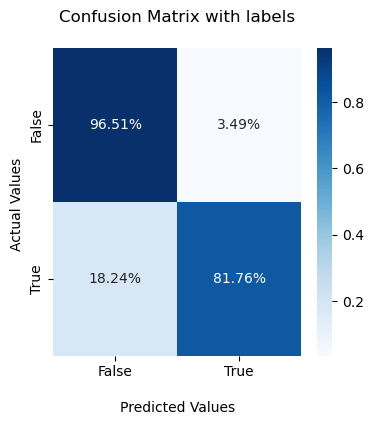

In [11]:
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.heatmap(cm_lpm_norm, annot=True, 
            fmt='.2%', cmap='Blues')

ax.set_title('Confusion Matrix with labels\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

plt.show()

**(b) For firms with a predicted probability of tax evasion greater than 0.6, construct the confusion matrix.**

In [12]:
# predicted probability > 0.6
y_pred_lpm = (p_validation > 0.6).astype(int)

cm_lpm = confusion_matrix(y_test, y_pred_lpm)
cm_lpm_norm = confusion_matrix(y_test, y_pred_lpm, normalize="true")
print(cm_lpm)
print(cm_lpm_norm)

[[225   4]
 [ 39 120]]
[[0.98253275 0.01746725]
 [0.24528302 0.75471698]]


In [13]:
(4+39)/(225+4+39+120)

0.11082474226804123

In [14]:
error_rate = (cm_lpm[0, 1] + cm_lpm[1, 0]) / cm_lpm.sum()
print(error_rate)

0.11082474226804123


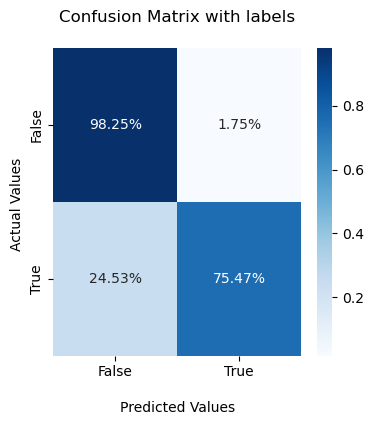

In [15]:
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.heatmap(cm_lpm_norm, annot=True, 
            fmt='.2%', cmap='Blues')

ax.set_title('Confusion Matrix with labels\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

plt.show()

**(c) For each of the two thresholds, report the error rate. Which results in more accurate overall predictions?**

The 0.5 threshold results in more accurate overall predictions because its error rate: 9.5%. The 0.6 threshold reaches an error rate of 11%.

**(d) For each of the two thresholds, what proportion of the firms predicted to evade their taxes actually evaded taxes?**

For the 0.5 threshold, 94%. And 97% for the 0.6 threshold.

**(e) Plot the ROC curve that illustrates the performance of your classifier and report the associated AUC score. Briefly explain how the ROC curve is an extension of the comparison in the previous parts of this question.**

/opt/miniconda3/envs/DAP/lib/python3.13/site-packages/sklearn/utils/_plotting.py:385: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


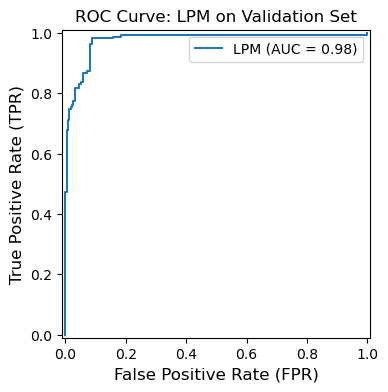

AUC: 0.976


In [16]:
fpr_lpm, tpr_lpm, thresholds_lpm = roc_curve(y_test, p_validation)
auc_lpm = roc_auc_score(y_test, p_validation)

roc_display = RocCurveDisplay(fpr=fpr_lpm, tpr=tpr_lpm,
                              roc_auc=auc_lpm,
                              estimator_name="LPM")

fig, ax = plt.subplots(figsize=(4, 4))
roc_display.plot(ax=ax)
ax.set_ylabel("True Positive Rate (TPR)", fontsize=12)
ax.set_xlabel("False Positive Rate (FPR)", fontsize=12)
ax.set_title("ROC Curve: LPM on Validation Set")
ax.legend()
plt.show()

print(f"AUC: {auc_lpm:.3f}")

**4. In measuring performance in this context, should a false negative matter as much as a false positive? Briefly explain why or why not and how changing the threshold for classifying a firm as a tax evader (as in the previous question) affects this trade-off.**

Not really. At least in this context, a false negative should matter more than a negative. This is because a false negative will never get audited, making the government lose tax revenue. 

In the other hand, a false positive is jut a firm that gets audited and potentially changes its risk profile.

**5. Using the training set from the previous question, fit a KNN model with k= 5, then use it to predict outcomes in the validation set with a threshold of 0.5.**

In [17]:
knn_5 = KNeighborsClassifier(n_neighbors = 5)
knn_5.fit(X_train, y_train)
p_knn_5 = knn_5.predict_proba(X_test)[:, 1]
knn_5_pred = (p_knn_5 > 0.5).astype(int)
accuracy_score(y_test, knn_5_pred)

0.9639175257731959

In [18]:
cm_knn_5 = confusion_matrix(y_test, knn_5_pred)
cm_knn_5_norm = confusion_matrix(y_test, knn_5_pred, normalize = "true")
print(cm_knn_5)
print(cm_knn_5_norm)

[[226   3]
 [ 11 148]]
[[0.98689956 0.01310044]
 [0.06918239 0.93081761]]


**(b) Report the error rate. How accurate are the overall predictions?**

The error rate is 3.61%, so the overall accuracy is about 96.4%.

In [19]:
(cm_knn_5[0, 1] + cm_knn_5[1, 0]) / cm_knn_5.sum()

np.float64(0.03608247422680412)

**(c) What proportion of the firms predicted to evade their taxes actually evaded taxes?**

98%!

In [20]:
cm_knn_5[1, 1] / (cm_knn_5[0, 1] + cm_knn_5[1, 1])

np.float64(0.9801324503311258)

**6. Repeat the previous question with k= 5 after scaling your predictors.**

In [21]:
scaler = StandardScaler()  # Initialize the scaler

X_train_scaled = scaler.fit_transform(X_train)  # learn mean & sd from training set only
X_test_scaled = scaler.transform(X_test)        # apply the same mean & sd to validation set

# convert back to dataframes, keeping column names and original row index
cols = X_train.columns
X_train_scaled = pd.DataFrame(X_train_scaled, columns = cols, index = X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = cols, index = X_test.index)

X_train_scaled.head()

,Sector_score,PARA_A,Risk_A,PARA_B,Risk_B,Money_Value,Risk_D,Score,Inherent_Risk,Audit_Risk
697,1.421475,-0.241126,-0.266723,-0.407467,-0.393729,-0.214519,-0.209945,-0.542222,-0.297419,-0.303256
414,-0.773175,0.567544,0.594397,-0.407467,-0.393729,-0.203613,-0.206312,0.448758,-0.191959,0.190116
584,1.421475,0.664853,0.690815,1.618981,1.626171,3.515881,3.517860,2.678463,3.377939,13.132027
555,1.596328,-0.410578,-0.382537,-0.407467,-0.393729,-0.061247,-0.056780,-0.294477,-0.180603,-0.232673
383,-0.767456,-0.348502,-0.362034,-0.407467,-0.393729,-0.213929,-0.209749,-0.542222,-0.296135,-0.279494


In [22]:
knn_5_scaled = KNeighborsClassifier(n_neighbors = 5)
knn_5_scaled.fit(X_train_scaled, y_train)
p_knn_5_scaled = knn_5_scaled.predict_proba(X_test_scaled)[:, 1]
knn_5_scaled_pred = (p_knn_5_scaled > 0.5).astype(int)

error_rate_knn_5_scaled = (knn_5_scaled_pred != y_test).mean()

In [23]:
cm_knn_5_scaled = confusion_matrix(y_test, knn_5_scaled_pred)
cm_knn_5_scaled_norm = confusion_matrix(y_test, knn_5_scaled_pred, normalize = "true")
print(cm_knn_5_scaled)
print(cm_knn_5_scaled_norm)

[[221   8]
 [ 12 147]]
[[0.9650655 0.0349345]
 [0.0754717 0.9245283]]


**(b) Report the error rate. How accurate are the overall predictions?**

5% error rate. So overall accuracy is 95%

In [24]:
(cm_knn_5_scaled[0, 1] + cm_knn_5_scaled[1, 0]) / cm_knn_5_scaled.sum()

np.float64(0.05154639175257732)

**(c) What proportion of the firms predicted to evade their taxes actually evaded taxes?**

95%

In [25]:
cm_knn_5_scaled[1, 1] / (cm_knn_5_scaled[0, 1] + cm_knn_5_scaled[1, 1])

np.float64(0.9483870967741935)

**(7) Which KNN model performs better: with or without the predictors normalized? Briefly explain how you make this determination and why you think this is the case.**

KNN without scaling. This one has lower overall error rate. 

**(8) For KNN, which k yields the lowest error rate? By 5-fold cross-validation (5FCV), find the k with the lowest classification error rate. Briefly explain.**

With 5FCV, k = 1 gives the lowest error rate, 2.06%. That’s the most flexible KNN model possible: each firm is classified by copying its single closest neighbor.

In [26]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(n_splits = 5, shuffle = True, random_state = 13)

k_values = range(1, 51)
cv_errors = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors = k)
    accuracy = cross_val_score(knn, X, y, cv = kfold, scoring = "accuracy")
    cv_errors.append(1 - accuracy.mean())      # error rate = 1 - accuracy

best_k = k_values[np.argmin(cv_errors)]
print(f"Best k: {best_k}")
print(f"5FCV error rate at best k: {min(cv_errors):.2%}")

Best k: 1
5FCV error rate at best k: 2.06%


**(9) In the long run, what problem might arise from the nature of the sample if the government heavily uses your best KNN model to target audits? Hint: the firms in the data are all firms that were audited.**

Because the model was trained only on firms that were already suspected and audited, relying on it would keep auditing firms that look like past evaders and miss evaders who look different, so its blind spots would grow over time.